# ПР-11. Понижение размерности методом главных компонент

Данные `o_churn_synthetic.csv` из ПР-8: 3000 абонентов, целевой признак `churn` (1 = ушёл). **Датасет синтетический, это не данные реального оператора.**

После one-hot кодирования `region` и `tariff` получается 22 признака, этого достаточно для PCA (условие: не меньше 10). Разбиение то же, что в ПР-8 и ПР-9: 80/20 со стратификацией и `random_state=42`.

Вариант B: оценить, как PCA влияет на качество модели и время обучения, и решить, нужен ли он в этой задаче. Сначала выполняю и обязательную часть: график накопленной дисперсии и проекцию на две компоненты.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_PATH = "../data/o_churn_synthetic.csv"
SEED = 42
CAT = ["region", "tariff"]

df = pd.read_csv(DATA_PATH)
X = df.drop(columns=["churn", "subscriber_code"])
y = df["churn"]
NUM = [c for c in X.columns if c not in CAT]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)


def make_prep():
    """One-hot для категорий и StandardScaler для всего, как требует PCA."""
    return make_pipeline(
        ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)],
                          remainder="passthrough"),
        StandardScaler())


prep = make_prep().fit(X_train)
names = prep[0].get_feature_names_out()
print("train:", X_train.shape, "test:", X_test.shape)
print("признаков после one-hot:", len(names))
print("scikit-learn", sklearn.__version__)

train: (2400, 11) test: (600, 11)
признаков после one-hot: 22
scikit-learn 1.9.1


## Веха 11.1. Объяснённая дисперсия

PCA ищет направления, вдоль которых данные сильнее всего меняются. Перед этим все признаки привожу к среднему 0 и стандартному отклонению 1 (`StandardScaler`), причём масштабирование обучаю **только на train**. PCA тоже обучаю на train: обучить его на всех данных до разбиения было бы такой же утечкой, как и масштабирование до разбиения.

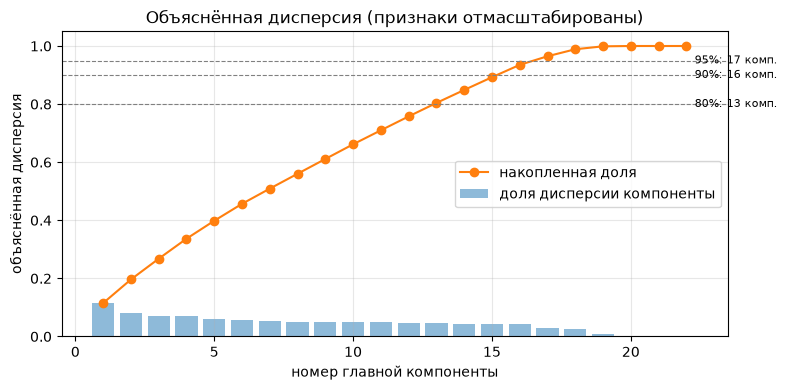

первые 5 компонент: [0.115 0.081 0.071 0.069 0.062]  две первые вместе: 0.196
компонент для 80 / 90 / 95 % дисперсии: {0.8: 13, 0.9: 16, 0.95: 17} из 22


In [2]:
Z_train = prep.transform(X_train)          # масштабирование обучено только на train
pca_full = PCA(random_state=SEED).fit(Z_train)
ratio = pca_full.explained_variance_ratio_
cum = np.cumsum(ratio)
need = {p: int(np.searchsorted(cum, p) + 1) for p in (0.8, 0.9, 0.95)}

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, len(ratio) + 1), ratio, alpha=0.5, label="доля дисперсии компоненты")
ax.plot(range(1, len(cum) + 1), cum, "o-", color="C1", label="накопленная доля")
for p, n in need.items():
    ax.axhline(p, ls="--", lw=0.8, color="gray")
    ax.text(len(cum) + 0.3, p, f"{p:.0%}: {n} комп.", va="center", fontsize=8)
ax.set(xlabel="номер главной компоненты", ylabel="объяснённая дисперсия",
       title="Объяснённая дисперсия (признаки отмасштабированы)")
ax.legend(loc="center right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("первые 5 компонент:", np.round(ratio[:5], 3), " две первые вместе:", round(cum[1], 3))
print("компонент для 80 / 90 / 95 % дисперсии:", need, "из", len(ratio))

**Сколько компонент нужно.** Чтобы сохранить 90% дисперсии, нужно **16 компонент из 22**, для 80% нужно 13, для 95% нужно 17. Первая компонента объясняет всего 11,5%, следующие по 6–8%: дисперсия распределена почти равномерно. Значит, признаки мало коррелируют друг с другом и сжимать почти нечего: PCA выигрывает, когда много признаков дублируют друг друга, а здесь это не так.

Для сравнения, что было бы без масштабирования:

In [3]:
# Для сравнения: PCA без масштабирования
raw = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)],
                        remainder="passthrough").fit(X_train)
pca_raw = PCA().fit(raw.transform(X_train))
top = pd.Series(np.abs(pca_raw.components_[0]), index=raw.get_feature_names_out()).sort_values(ascending=False)
print("без масштабирования PC1 объясняет", round(pca_raw.explained_variance_ratio_[0], 3), "дисперсии")
print("наибольшие веса в PC1:", top.head(3).round(3).to_dict())

без масштабирования PC1 объясняет 0.927 дисперсии
наибольшие веса в PC1: {'remainder__monthly_charge_som': 1.0, 'remainder__internet_gb': 0.022, 'remainder__days_since_topup': 0.002}


Без масштабирования первая компонента «объясняет» 92,7% дисперсии и почти целиком состоит из `monthly_charge_som` (вес 1,00). Это не значит, что платёж главный признак: просто у него самый большой разброс в сомах (std около 190), а у остальных единицы. PCA на немасштабированных данных находит признак с самыми большими числами, а не самый информативный.

## Веха 11.2. Проекция на две главные компоненты

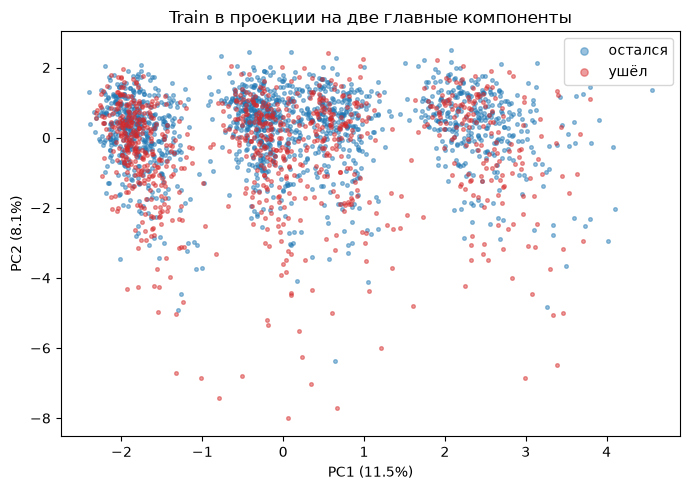

In [4]:
P2 = pca_full.transform(Z_train)[:, :2]
fig, ax = plt.subplots(figsize=(7, 5))
for cls, color, label in [(0, "C0", "остался"), (1, "C3", "ушёл")]:
    m = (y_train == cls).to_numpy()
    ax.scatter(P2[m, 0], P2[m, 1], s=7, alpha=0.45, color=color, label=label)
ax.set(xlabel=f"PC1 ({ratio[0]:.1%})", ylabel=f"PC2 ({ratio[1]:.1%})",
       title="Train в проекции на две главные компоненты")
ax.legend(markerscale=2)
plt.tight_layout()
plt.show()

Две первые компоненты вместе объясняют **19,6%** дисперсии, меньше 40%. Поэтому двумерная картинка мало информативна, и это видно: ушедшие и оставшиеся абоненты полностью перемешаны, никакой границы между ними на плоскости PC1–PC2 нет. Это результат, а не ошибка: 80% информации о данных на этой картинке просто не видно.

Из чего состоят первые компоненты (веса признаков, 8 самых больших по PC1):

In [5]:
load = pd.DataFrame(pca_full.components_[:3].T, index=names, columns=["PC1", "PC2", "PC3"])
load.reindex(load["PC1"].abs().sort_values(ascending=False).index).round(3).head(8)

,PC1,PC2,PC3
remainder__monthly_charge_som,0.607,0.058,-0.025
cat__tariff_Безлимит,0.505,0.031,0.096
cat__tariff_Базовый,-0.490,-0.063,0.220
remainder__internet_gb,0.326,-0.020,0.052
cat__tariff_Семейный,0.124,0.034,0.081
remainder__days_since_topup,0.066,-0.695,-0.017
remainder__topups_3m,-0.055,0.696,0.008
cat__tariff_Смарт,-0.046,0.010,-0.377


Главная компонента это **не какой-то исходный признак, а линейная комбинация всех 22**. По весам её можно примерно описать:

- **PC1 ≈ «дорогой тариф»**: большой вклад `monthly_charge_som` (0,61), `tariff_Безлимит` (0,51), `internet_gb` (0,33) и с минусом `tariff_Базовый` (−0,49). Платёж и тариф сильно связаны, PCA объединил их в одно направление.
- **PC2 ≈ «давно не пополнял»**: `days_since_topup` (−0,70) и `topups_3m` (0,70) с противоположными знаками, то есть мало пополнений и давнее последнее пополнение.

Отток сильнее всего связан с поведением пополнения, а оно попало во вторую компоненту, а не в первую. PCA не знает про целевой признак и упорядочивает компоненты по дисперсии, а не по пользе для предсказания.

## Веха 11.3. Базовые модели без PCA

Беру две модели из прошлых работ: логистическую регрессию (лучшая в ПР-8) и случайный лес на 300 деревьев. Качество считаю 5-кратной стратифицированной кросс-валидацией на train (ROC-AUC) и на test. Время обучения на всём train замеряю отдельно.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def evaluate(name, model, n_components=None):
    steps = [make_prep()] + ([PCA(n_components=n_components, random_state=SEED)] if n_components else []) + [model]
    pipe = make_pipeline(*steps)
    cvres = cross_validate(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    fit_sec = time.perf_counter() - t0
    k = pipe[-2].n_components_ if n_components else len(names)
    return {"Модель": name, "PCA": "нет" if not n_components else f"{n_components}",
            "признаков": k, "ROC-AUC CV": cvres["test_score"].mean(), "± (std)": cvres["test_score"].std(),
            "ROC-AUC test": roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1]),
            "обучение, с": fit_sec}


rows = [evaluate("Логрегрессия", LogisticRegression(max_iter=1000)),
        evaluate("Случайный лес", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1))]
pd.DataFrame(rows).set_index("Модель").round(4)

,PCA,признаков,ROC-AUC CV,± (std),ROC-AUC test,"обучение, с"
Модель,,,,,,
Логрегрессия,нет,22,0.7774,0.0148,0.8058,0.0033
Случайный лес,нет,22,0.7562,0.0155,0.7606,0.4178


## Веха 11.4. Пайплайн со встроенным PCA

Пайплайн: one-hot → `StandardScaler` → `PCA` → модель. PCA стоит **внутри пайплайна**, поэтому в каждом фолде кросс-валидации он обучается только на обучающей части фолда, и утечки нет. Число компонент задаю долей сохраняемой дисперсии: 80%, 90%, 95%.

In [7]:
for share in [0.8, 0.9, 0.95]:
    rows.append(evaluate("Логрегрессия", LogisticRegression(max_iter=1000), share))
for share in [0.8, 0.9, 0.95]:
    rows.append(evaluate("Случайный лес", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1), share))
summary = pd.DataFrame(rows).set_index(["Модель", "PCA"])
summary.round(4)

признаков  ROC-AUC CV  ± (std)  ROC-AUC test  обучение, с
Модель        PCA                                                            
Логрегрессия  нет          22      0.7774   0.0148        0.8058       0.0033
Случайный лес нет          22      0.7562   0.0155        0.7606       0.4178
Логрегрессия  0.8          13      0.7350   0.0267        0.7196       0.0027
              0.9          16      0.7726   0.0178        0.7838       0.0028
              0.95         17      0.7753   0.0171        0.7900       0.0028
Случайный лес 0.8          13      0.7219   0.0245        0.7151       0.6854
              0.9          16      0.7356   0.0234        0.7272       0.8526
              0.95         17      0.7368   0.0220        0.7342       0.8579

И для полноты несколько совсем маленьких чисел компонент:

In [8]:
small = []
for k in [1, 2, 3, 5, 8]:
    r = evaluate("Логрегрессия", LogisticRegression(max_iter=1000), k)
    small.append({"компонент": k, "ROC-AUC CV": r["ROC-AUC CV"]})
pd.DataFrame(small).set_index("компонент").round(4)

,ROC-AUC CV
компонент,
1,0.5211
2,0.6203
3,0.6430
5,0.6459
8,0.6601


## Итог

| Модель | PCA | Признаков | ROC-AUC CV | ROC-AUC test |
| --- | --- | --- | --- | --- |
| Логрегрессия | нет | 22 | **0,777** | **0,806** |
| Логрегрессия | 95% | 17 | 0,775 | 0,790 |
| Логрегрессия | 90% | 16 | 0,773 | 0,784 |
| Логрегрессия | 80% | 13 | 0,735 | 0,720 |
| Случайный лес | нет | 22 | **0,756** | **0,761** |
| Случайный лес | 95% | 17 | 0,737 | 0,734 |
| Случайный лес | 90% | 16 | 0,736 | 0,727 |
| Случайный лес | 80% | 13 | 0,722 | 0,715 |

Сравнение по трём показателям:

- **Качество.** PCA его только снижает. У логистической регрессии при 95% и 90% дисперсии потеря небольшая (0,002–0,005 на кросс-валидации, это в пределах разброса между фолдами 0,015), а при 80% уже заметная (−0,04). Случайный лес теряет 0,02–0,03 при любом числе компонент. С 1–8 компонентами ROC-AUC падает до 0,52–0,66: «информативная» для оттока часть дисперсии сидит не в первых компонентах.
- **Время обучения.** Логистическая регрессия обучается за 3 мс и с PCA, и без него, выигрыша нет. Случайный лес с PCA обучается даже **дольше**: 0,70–0,86 с против 0,41 с. После поворота осей каждая компонента это непрерывная смесь всех признаков, вместо восьми значений `support_calls_3m` (0–7) или двух значений `autopay` у деревьев много уникальных порогов для перебора. (Точное время немного меняется от запуска к запуску.)
- **Число признаков.** Сокращается с 22 до 16–17, всего на четверть.

**Вывод: в этой задаче PCA не даёт выигрыша, применять его не стоит.** Причины:

1. Признаков мало (22), модели и так обучаются за доли секунды, ускорять нечего.
2. Признаки почти не коррелируют: для 90% дисперсии нужно 16 компонент из 22, сжатие слабое.
3. PCA выбирает направления по дисперсии, а не по связи с целевым признаком, поэтому даже 95% дисперсии теряют часть полезной информации.
4. Модель на компонентах труднее объяснить: вместо «много звонков в поддержку» получается «высокое значение PC7».

PCA оправдан, когда признаков сотни и тысячи и многие из них дублируют друг друга (пиксели изображений, тексты, датчики), или для визуализации. Но и тогда при 2 компонентах с 19,6% дисперсии, как здесь, картинка мало что показывает.